# Who Do We Call First? Prioritizing CRM Leads with PCA
Moldir Assanova, Sayat Uvazhanov · CS 5130

**Problem.** iBEC got 330 leads from ads. Sales needs to know who to call first. A simple sum of the form answers fails: IBEC-00113 and IBEC-00049 both score 12, but the first is a huge company with no budget, and the second is a small company with a budget and a spec.

**Idea.** We turn 7 form answers into 2 scores with PCA. We find the axes two ways: eigenvectors with power iteration (Part 1) and SVD (Part 2). Both give the same axes.

**Data.** `iBEC_Systems_inbound_leads.csv`: 330 leads, 19 columns.

### Equation numbers (they match the slides)

| Eq. | Formula | Shapes | Course topic |
|---|---|---|---|
| (1) | $Z = (X - \mu) / s$ | $237\times7 \to 237\times7$ | Week 1: vectors, matrices |
| (2) | $C = Z^T Z / (n-1)$ | $(7\times237)(237\times7) \to 7\times7$ | Week 1: matrix product |
| (3) | $C v = \lambda v$ | $(7\times7)(7) \to 7$ | Week 3: eigenvalues |
| (4) | $v \leftarrow C v / \lVert C v \rVert$ | $7 \to 7$ | Week 3: power iteration |
| (5) | $Z = U \Sigma V^T$ | $237\times7 = (237\times7)(7\times7)(7\times7)$ | Week 3: SVD |
| (6) | $\lambda = \sigma^2 / (n-1)$ | numbers | Week 3: SVD and eigenvalues |
| (7) | $u_k = Z v_k / \sigma_k$ | $(237\times7)(7) \to 237$ | Week 3: orthogonality |
| (8) | $\lVert Z - Z_k \rVert^2 = \sum_{i>k} \sigma_i^2$ | number | Week 4: approximation error |
| (9) | $\mathrm{cond}(Z^TZ) = \mathrm{cond}(Z)^2$ | numbers | Week 4: numerical stability |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('iBEC_Systems_inbound_leads.csv')
print(df.shape)
df.head()


(330, 19)


,lead_id,submitted_at_utc,source,campaign,country,company_name,contact_name,job_title,email,phone,has_it_strategy,has_requirements_spec,has_technical_team,company_stage,company_size,project_budget_usd,planned_start,product_type,message
0,IBEC-00001,2026-08-03T18:02:00Z,Facebook,custom_software_facebook,USA,NorthStone Travel,Amelia Collins,Head of Operations,team@northstonetravel-132.example.com,NaN,No,No,Yes,Growing,1–10,Not allocated,1–3 months,Mobile application,123
1,IBEC-00002,2026-08-04T02:28:00Z,Instagram,custom_software_instagram,USA,NovaWave Services,James Turner,Head of Operations,hello@novawaveservices-213.example.com,NaN,No,Yes,No,Growing,11–50,Not allocated,Later than 6 months / exploring,Mobile application,Just researching prices. No project owner or f...
2,IBEC-00003,2026-08-04T03:37:00Z,Facebook,custom_software_facebook,USA,BlueRise Travel,Noah Patel,COO,team@bluerisetravel-74.example.com,NaN,Yes,No,No,Mature,1–10,30000–99999,Later than 6 months / exploring,Mobile application,Interested in a customer booking app with paym...
3,IBEC-00004,2026-08-04T08:46:00Z,LinkedIn,custom_software_linkedin,UK,RiverWorks Services,Amelia Collins,Founder,office@riverworksservices-287.example.com,NaN,No,No,No,Startup,1–10,NaN,1–3 months,ERP,Interested in a production planning system wit...
4,IBEC-00005,2026-08-04T10:41:00Z,Facebook,custom_software_facebook,UK,NorthWave Manufacturing,Sofia Collins,COO,office@northwavemanufacturing-51.example.com,NaN,No,Yes,No,Growing,1–10,30000–99999,Within 1 month,Mobile application,Need a customer booking app with payments. Hap...


---
# Part 1: PCA with eigenvectors

### Step 1: clean the data and turn answers into numbers
We keep leads with a working email (330 → 312), remove the same email sent twice (→ 292), and drop leads with an empty answer, because PCA needs all 7 answers (→ 237).

Then we turn each answer into a number and keep the order: a bigger answer gets a bigger number. Result: matrix $X$, 237 × 7, one row per lead and one column per answer.


In [2]:
# Cleaning step 1: email is our only contact, keep only working emails
def has_email(email):
    return '@' in email and '.' in email

df['email'] = df['email'].fillna('')
df = df[df['email'].apply(has_email)]
print(df.shape)


(312, 19)


In [3]:
# Cleaning step 2: same email twice = same person sent the form twice
df = df.drop_duplicates(subset='email')
print(df.shape)


(292, 19)


In [4]:
# Cleaning step 3: PCA needs all seven answers, drop leads with empty answers
form = ['has_it_strategy', 'has_requirements_spec', 'has_technical_team',
        'company_stage', 'company_size', 'project_budget_usd', 'planned_start']
print(df[form].isnull().sum())

df_292 = df   # keep for the experiment: fill empty answers instead of dropping
df = df.dropna(subset=form)
print(df.shape)


has_it_strategy          11
has_requirements_spec    18
has_technical_team       23
company_stage             5
company_size             17
project_budget_usd       22
planned_start             6
dtype: int64
(237, 19)


In [5]:
# Encoding: answers -> numbers, order kept (bigger answer = bigger number)
yes_no = {'No': 0, 'Yes': 1}
stage = {'Startup': 1, 'Growing': 2, 'Mature': 3}
size = {'1–10': 1, '11–50': 2, '51–200': 3, '201–1000': 4, '1001+': 5}
budget = {'Not allocated': 0, '<10000': 1, '10000–29999': 2, '30000–99999': 3, '100000+': 4}
start = {'Later than 6 months / exploring': 1, '3–6 months': 2, '1–3 months': 3, 'Within 1 month': 4}

leads = pd.DataFrame()
leads['it_strategy'] = df['has_it_strategy'].map(yes_no)
leads['has_spec'] = df['has_requirements_spec'].map(yes_no)
leads['tech_team'] = df['has_technical_team'].map(yes_no)
leads['stage'] = df['company_stage'].map(stage)
leads['size'] = df['company_size'].map(size)
leads['budget'] = df['project_budget_usd'].map(budget)
leads['start'] = df['planned_start'].map(start)
print(leads.isnull().sum().sum())   # 0 = every answer got a number

X = np.array(leads, dtype=float)    # X: 237 x 7
print(X.shape)
leads.head()


0
(237, 7)


,it_strategy,has_spec,tech_team,stage,size,budget,start
0,0,0,1,2,1,0,3
1,0,1,0,2,2,0,1
2,1,0,0,3,1,3,1
4,0,1,0,2,1,3,4
6,1,1,1,3,3,3,1


### Step 2: one scale for all answers, then which answers move together (Eq. 1, 2)
Budget goes from 0 to 4, while yes/no answers go from 0 to 1. Without a common scale, the answer with the widest range wins. So in every column we subtract the mean and divide by the std (Eq. 1). Now 0 means an average lead.

Then we build the covariance matrix $C = Z^T Z / (n-1)$ (Eq. 2), shape 7 × 7. Each cell shows if two answers grow together. We divide by $n-1$ to match `np.cov`.

In [6]:
# Standardize: Z = (X - mean) / std, column by column   Eq. (1)
mean = X.mean(axis=0)             # 7 means, one per column
std = X.std(axis=0, ddof=1)       # 7 stds, one per column
Z = (X - mean) / std              # Z: 237 x 7
print(mean.round(2))
print(std.round(2))
print(Z.mean(axis=0).round(2))    # check: every column mean is now 0
print(Z.std(axis=0, ddof=1).round(2))   # check: every column std is now 1


[0.38 0.34 0.33 1.86 2.07 1.84 2.5 ]
[0.49 0.47 0.47 0.71 1.05 1.37 1.12]
[-0.  0.  0.  0. -0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1.]


In [7]:
# Covariance matrix: C = Z^T Z / (n - 1)   Eq. (2)
n = Z.shape[0]                       # 237 leads
C = Z.T @ Z / (n - 1)                # C: 7 x 7
print(C.shape)
print(np.allclose(C, np.cov(Z.T)))   # check against the library
pd.DataFrame(C, index=leads.columns, columns=leads.columns).round(2)


(7, 7)
True


,it_strategy,has_spec,tech_team,stage,size,budget,start
it_strategy,1.00,-0.01,0.17,0.24,0.35,-0.01,0.01
has_spec,-0.01,1.00,-0.01,-0.06,0.06,0.17,0.08
tech_team,0.17,-0.01,1.00,0.14,0.17,0.05,0.03
stage,0.24,-0.06,0.14,1.00,0.46,0.09,-0.03
size,0.35,0.06,0.17,0.46,1.00,0.02,-0.01
budget,-0.01,0.17,0.05,0.09,0.02,1.00,0.14
start,0.01,0.08,0.03,-0.03,-0.01,0.14,1.00


### Step 3: find PC1 with power iteration (Eq. 3, 4)
When we multiply an eigenvector by $C$, it keeps its direction and only gets longer by $\lambda$ (Eq. 3). Power iteration finds the strongest one: start with equal weights, multiply by $C$, scale back to length 1, repeat (Eq. 4). Shapes: $C$ is 7 × 7, $v$ has 7 numbers.

We run 100 rounds, as in Week 3. Our checks pass after about 45.

Power iteration gives only the first axis. We take PC2 from `np.linalg.eigh` and use it to check our PC1 too.


In [8]:
# Power iteration for PC1: v <- C v / ||C v||   Eq. (4)
v = np.ones(7) / np.sqrt(7)       # start: equal weights, length 1
for i in range(100):
    w = C @ v                     # multiply by C
    v = w / np.linalg.norm(w)     # scale back to length 1
    if i in [0, 2, 5]:
        print(i + 1, v.round(2))
print('final', v.round(2))

lam = np.linalg.norm(C @ v)       # lambda: how much C stretches v
print('lambda', lam.round(3))
print(np.allclose(C @ v, lam * v))   # check: C v = lambda v, Eq. (3)


1 [0.41 0.29 0.36 0.43 0.48 0.34 0.29]
3 [0.45 0.16 0.34 0.5  0.56 0.24 0.15]
6 [0.48 0.07 0.33 0.54 0.59 0.15 0.06]
final [0.48 0.02 0.32 0.55 0.59 0.1  0.01]
lambda 1.805
True


In [9]:
# All axes with the library: eigh solves C v = lambda v, Eq. (3); sorted from largest (as in Week3.ipynb)
eigenvalues, eigenvectors = np.linalg.eigh(C)
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

pc1 = eigenvectors[:, 0]
pc2 = eigenvectors[:, 1]
if pc1[4] < 0:      # an axis and its opposite are the same; keep size positive
    pc1 = -pc1
if pc2[5] < 0:      # keep budget positive
    pc2 = -pc2

print(np.allclose(pc1, v))     # check: our power iteration = library
print('lambda', eigenvalues.round(3))
print('PC2', pc2.round(2))
share = eigenvalues / eigenvalues.sum() * 100
print('share %', share.round(1))


True
lambda [1.805 1.266 0.948 0.894 0.868 0.725 0.494]
PC2 [-0.09  0.57  0.05 -0.07 -0.02  0.63  0.52]
share % [25.8 18.1 13.5 12.8 12.4 10.4  7.1]


### Step 4: each lead becomes a dot
Score = $Z$ times the axis: (237 × 7)(7) → 237 numbers. score1 (PC1, size and maturity) is x, score2 (PC2, project readiness) is y.

The two leads with the same sum of 12 land far apart on the map.


IBEC-00113 [2.78] [-1.32]
IBEC-00049 [0.26] [1.68]


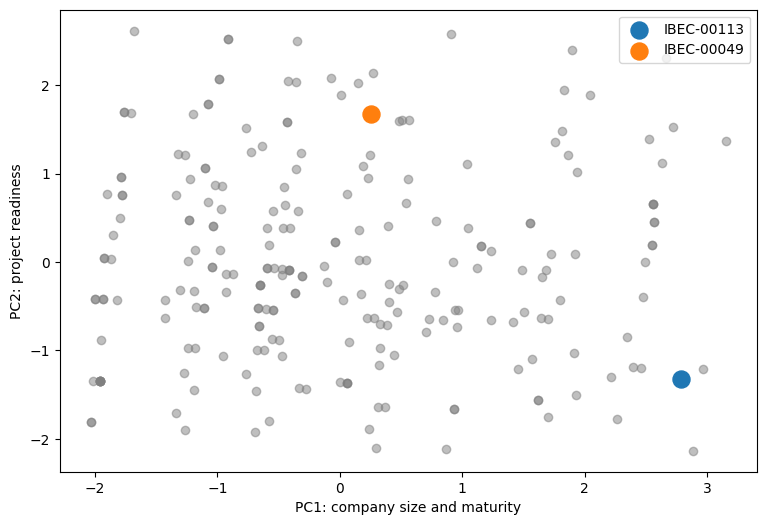

In [10]:
# Each lead becomes a dot: score = Z @ axis   (237 x 7 times 7 -> 237 numbers)
score1 = Z @ pc1     # PC1: size and maturity
score2 = Z @ pc2     # PC2: project readiness

ids = np.array(df['lead_id'])
a = ids == 'IBEC-00113'
b = ids == 'IBEC-00049'
print('IBEC-00113', score1[a].round(2), score2[a].round(2))
print('IBEC-00049', score1[b].round(2), score2[b].round(2))

plt.figure(figsize=(9, 6))
plt.scatter(score1, score2, alpha=0.5, color='gray')
plt.scatter(score1[a], score2[a], s=150, color='tab:blue', label='IBEC-00113')
plt.scatter(score1[b], score2[b], s=150, color='tab:orange', label='IBEC-00049')
plt.xlabel('PC1: company size and maturity')
plt.ylabel('PC2: project readiness')
plt.legend()
plt.show()


In [11]:
# Experiment: PCA without standardizing (only subtract the mean) vs with
Xc = X - X.mean(axis=0)                # Eq. (1) without dividing by std
C_raw = Xc.T @ Xc / (n - 1)            # Eq. (2) on raw scales
vals_raw, vecs_raw = np.linalg.eigh(C_raw)
idx = vals_raw.argsort()[::-1]
pc1_raw = vecs_raw[:, idx[0]]
if pc1_raw[5] < 0:
    pc1_raw = -pc1_raw

table = pd.DataFrame({'without standardizing': pc1_raw, 'with standardizing': pc1},
                     index=leads.columns)
table.round(2)


,without standardizing,with standardizing
it_strategy,0.01,0.48
has_spec,0.07,0.02
tech_team,0.02,0.32
stage,0.07,0.55
size,0.07,0.59
budget,0.95,0.10
start,0.30,0.01


In [12]:
# Experiment: drop leads with empty answers (237) vs fill them with column mean (292)
filled = pd.DataFrame()
filled['it_strategy'] = df_292['has_it_strategy'].map(yes_no)
filled['has_spec'] = df_292['has_requirements_spec'].map(yes_no)
filled['tech_team'] = df_292['has_technical_team'].map(yes_no)
filled['stage'] = df_292['company_stage'].map(stage)
filled['size'] = df_292['company_size'].map(size)
filled['budget'] = df_292['project_budget_usd'].map(budget)
filled['start'] = df_292['planned_start'].map(start)
print(filled.isnull().sum().sum())     # 102 empty cells before filling
filled = filled.fillna(filled.mean())

X2 = np.array(filled, dtype=float)     # X2: 292 x 7
Z2 = (X2 - X2.mean(axis=0)) / X2.std(axis=0, ddof=1)   # Eq. (1)
C2 = Z2.T @ Z2 / (len(Z2) - 1)                         # Eq. (2)
vals2, vecs2 = np.linalg.eigh(C2)                      # Eq. (3)
idx = vals2.argsort()[::-1]
vals2 = vals2[idx]
vecs2 = vecs2[:, idx]
pc1_fill = vecs2[:, 0]
pc2_fill = vecs2[:, 1]
if pc1_fill[4] < 0:
    pc1_fill = -pc1_fill
if pc2_fill[5] < 0:
    pc2_fill = -pc2_fill

print(X2.shape)
print('share % drop:', share[:2].round(1), ' fill:', (vals2 / vals2.sum() * 100)[:2].round(1))
print('same axis? (1 = identical)', abs(pc1 @ pc1_fill).round(3), abs(pc2 @ pc2_fill).round(3))
pd.DataFrame({'PC1 drop': pc1, 'PC1 fill': pc1_fill, 'PC2 drop': pc2, 'PC2 fill': pc2_fill},
             index=leads.columns).round(2)


102
(292, 7)
share % drop: [25.8 18.1]  fill: [25.8 18. ]
same axis? (1 = identical) 0.994 0.995


,PC1 drop,PC1 fill,PC2 drop,PC2 fill
it_strategy,0.48,0.49,-0.09,-0.09
has_spec,0.02,0.08,0.57,0.54
tech_team,0.32,0.32,0.05,0.03
stage,0.55,0.52,-0.07,-0.13
size,0.59,0.60,-0.02,-0.08
budget,0.10,0.09,0.63,0.64
start,0.01,0.10,0.52,0.52


**What we see.**
- Without standardizing, PC1 is almost only budget (0.95). Budget wins because its range is the widest. With standardizing, the pattern is size, stage, strategy and team.
- If we fill empty answers with the column mean (292 leads) instead of dropping them (237 leads), the axes stay almost the same: similarity 0.994 for PC1 and 0.995 for PC2, shares 25.8% and 18%. Dropping 55 leads did not change the result.


---
# Part 2: PCA computed with SVD, written by hand

In Part 1 the axes came from the **eigenvectors of the covariance matrix** $C$. Here we get the **same axes a second way**, with the singular value decomposition of the standardized data $Z$.

**Rule:** every step is written with basic NumPy (`@`, `.T`, `np.sqrt`, `np.linalg.norm`, `np.outer`). The library function `np.linalg.svd` is called **only in the last check**.

Equation numbers: see the table at the top.

### Plan
1. Find the eigenvectors of $M = Z^T Z$ with power iteration (Eq. 3, 4) and remove each one after we find it (deflation).
2. Build $\Sigma$, $V$ and $U$ from them (Eq. 5, 6, 7).
3. Check the result with pure math.
4. Two experiments: how many steps are needed, and how many axes to keep (Eq. 8).
5. Last: compare with the library.


### Step A: power iteration (Eq. 3 and Eq. 4)

**Idea.** An eigenvector $v$ of a matrix $M$ keeps its direction when we multiply by $M$: the matrix only stretches it by $\lambda$ (Eq. 3). If we start with any vector and keep multiplying by $M$ and scaling back to length 1 (Eq. 4), the vector turns toward the direction that $M$ stretches the most. That is the eigenvector with the **biggest** eigenvalue.

- shapes: $M$ is $7\times7$, $v$ and $Mv$ are vectors with 7 numbers
- the eigenvalue is then $\lambda = v^T M v$ (a $1\times7$ times $7\times7$ times $7\times1$ gives one number)

The function stops when $v$ stops changing, and returns $\lambda$, $v$ and the number of steps.

In [13]:
# Power iteration: finds the biggest eigenvalue and its eigenvector of a symmetric matrix M
# Goal,   Eq. (3): M v = lambda v          (M: 7x7, v: 7 numbers, lambda: one number)
# Method, Eq. (4): v <- M v / ||M v||      (repeat until v stops changing)
def power_iteration(M, max_iters=100000, tol=1e-14):
    v = np.arange(1, M.shape[0] + 1, dtype=float)   # start vector v0: 7 numbers, any non-zero start works
    v = v / np.linalg.norm(v)                       # make its length 1
    for i in range(max_iters):
        w = M @ v                                   # Eq. (4), top: multiply by M      (7x7)(7) -> 7
        w = w / np.linalg.norm(w)                   # Eq. (4), bottom: scale back to length 1
        if np.linalg.norm(w - v) < tol:             # direction stopped changing -> converged
            v = w
            break
        v = w
    lam = v @ M @ v                                 # Eq. (3) solved for lambda: v^T M v = lambda (since |v| = 1)
    return lam, v, i + 1                            # eigenvalue, eigenvector, number of steps used

### Step B: SVD by hand (Eq. 5, 6, 7)

We want $Z = U \Sigma V^T$ (Eq. 5), with shapes $U$: $237\times7$, $\Sigma$: $7\times7$, $V^T$: $7\times7$.

**Four steps:**
1. $M = Z^T Z$, shape $7\times7$ (this is Eq. 2 without dividing by $n-1$).
2. Find the eigenpairs of $M$ with power iteration. After each one **deflate**: $M \leftarrow M - \lambda v v^T$. This removes the axis we just found, so the next run finds the next biggest one.
3. The eigenvectors are the columns of $V$. The eigenvalue of $Z^TZ$ is $\sigma^2$, so $\sigma_k = \sqrt{\lambda_k}$. (The covariance matrix $C$ has the eigenvalue $\sigma^2/(n-1)$, this is Eq. 6.)
4. The left singular vectors come from Eq. 7: $u_k = Z v_k / \sigma_k$, so $U = (ZV)/\sigma$ with every column divided by its own $\sigma_k$.

`my_svd` returns $U$, the singular values $\sigma$, $V^T$ and the number of power-iteration steps for each axis.

In [14]:
# SVD by hand: Z = U Sigma V^T
def my_svd(Z):
    m, p = Z.shape
    M = Z.T @ Z                       # step 1: M = Z^T Z  (p x p, symmetric)

    sigma = np.zeros(p)               # singular values (the diagonal of Sigma)
    V = np.zeros((p, p))              # right singular vectors, one per column
    iters = []

    for k in range(p):                # step 2-3: find all p eigenpairs of M
        lam, v, it = power_iteration(M)
        sigma[k] = np.sqrt(lam)       # sigma = sqrt(lambda)
        V[:, k] = v
        iters.append(it)
        M = M - lam * np.outer(v, v)  # deflation: remove this axis, next biggest comes up

    U = (Z @ V) / sigma               # step 4: u_k = Z v_k / sigma_k (left singular vectors)
    return U, sigma, V.T, iters       # V.T = Vt, rows are the right singular vectors

U_my, s_my, Vt_my, iters = my_svd(Z)
print('U:', U_my.shape, ' sigma:', s_my.shape, ' Vt:', Vt_my.shape)   # (237,7) (7,) (7,7)
print('sigma:', s_my.round(3))
print('iterations per axis:', iters)
Sigma_my = np.diag(s_my)             # sigma on the diagonal of a 7 x 7 matrix

U: (237, 7)  sigma: (7,)  Vt: (7, 7)
sigma: [20.642 17.283 14.958 14.522 14.316 13.077 10.799]
iterations per axis: [89, 104, 497, 970, 173, 82, 2]


### Step C: checks with pure math (no SVD library)

- $Z = U\Sigma V^T$ (Eq. 5) reconstructs the data
- $U^TU = I$ and $V^TV = I$: the columns of $U$ and the columns of $V$ are orthonormal
- $\sigma^2/(n-1)$ equals the eigenvalues of $C$ (Eq. 6): this compares our SVD with the eigenvector method from Part 1
- the first two rows of $V^T$ are our axes PC1 and PC2; we use the same sign rule as in Part 1 (size positive, budget positive)

All checks should print `True`.

In [15]:
# Checks with pure math
print('Z = U Sigma Vt  :', np.allclose(U_my @ Sigma_my @ Vt_my, Z))
print('U^T U = I       :', np.allclose(U_my.T @ U_my, np.eye(7)))   # columns of U are orthonormal
print('V^T V = I       :', np.allclose(Vt_my @ Vt_my.T, np.eye(7)))  # rows of Vt are orthonormal
print('lambda = sigma^2/(n-1) = eigenvalues:', np.allclose(s_my**2 / (n - 1), eigenvalues))

# our two axes and lead scores (same sign rule as in the partner's code)
my1, my2 = Vt_my[0].copy(), Vt_my[1].copy()
if my1[4] < 0: my1 = -my1          # size positive
if my2[5] < 0: my2 = -my2          # budget positive

print('PC1:', my1.round(2))
print('PC2:', my2.round(2))

Z = U Sigma Vt  : True
U^T U = I       : True
V^T V = I       : True
lambda = sigma^2/(n-1) = eigenvalues: True
PC1: [0.48 0.02 0.32 0.55 0.59 0.1  0.01]
PC2: [-0.09  0.57  0.05 -0.07 -0.02  0.63  0.52]


### Experiment 1: how many power-iteration steps do we need?

**Question.** How many multiplications by $M$ (Eq. 4) does each axis need before $\sigma$ is accurate?

**What we vary.** The number of steps per axis: 5, 10, 25, 50, 100, 250, 500, 1000.
**What we measure.** The worst error of $\sigma$ over the 7 axes, compared with the converged result.

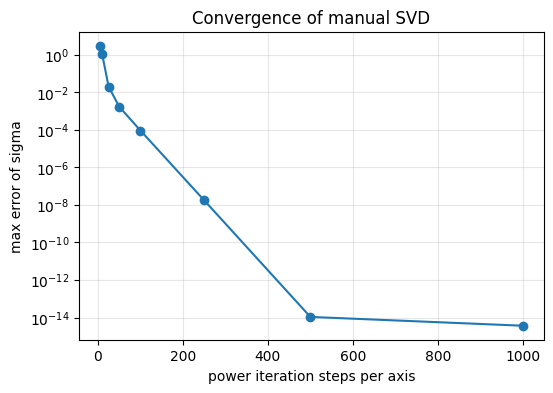

,steps,max error
0,5,3.078339e+00
1,10,1.062730e+00
2,25,2.049824e-02
3,50,1.728149e-03
4,100,9.295315e-05
5,250,1.768494e-08
6,500,1.065814e-14
7,1000,3.552714e-15


In [16]:
# Experiment 1: how many power-iteration steps do we need?
# error of sigma after a fixed number of steps, compared with the exact sigma (checked at the end)
steps_list = [5, 10, 25, 50, 100, 250, 500, 1000]
errors = []
for steps in steps_list:
    M = Z.T @ Z
    sig_k = np.zeros(7)
    for k in range(7):
        v = np.arange(1, 8, dtype=float); v = v / np.linalg.norm(v)
        for _ in range(steps):
            w = M @ v
            v = w / np.linalg.norm(w)
        lam = v @ M @ v
        sig_k[k] = np.sqrt(lam)
        M = M - lam * np.outer(v, v)
    errors.append(np.abs(sig_k - s_my).max())      # s_my = converged result

plt.figure(figsize=(6, 4))
plt.semilogy(steps_list, np.array(errors) + 1e-16, 'o-')
plt.xlabel('power iteration steps per axis'); plt.ylabel('max error of sigma')
plt.title('Convergence of manual SVD'); plt.grid(alpha=0.3)
plt.show()
pd.DataFrame({'steps': steps_list, 'max error': errors})

**What we see.**
- After 10 steps the error is about 1, after 100 steps about $10^{-4}$, after 500 steps it is at machine precision (about $10^{-14}$).
- On a log scale the error falls roughly along a straight line, so the method converges linearly (each step shrinks the error by a constant factor), then stops at rounding error.

**Why the steps differ by axis.** The speed depends on the ratio of two neighbouring eigenvalues. The 4th and 5th axes have almost equal strength ($\sigma_4 = 14.52$, $\sigma_5 = 14.32$), so power iteration separates them slowly: in the run above the 4th axis needs about 970 steps, while the 7th needs only 2.


## Experiment 2: Truncation Error

### Objective
The goal of this experiment is to measure how much information is lost when we keep only the first k principal components.

### Method
1. Select the first k singular values and corresponding components.
2. Reconstruct the original standardized matrix using only these k components.
3. Calculate the reconstruction error.
4. Compare the measured error with the theoretical truncation error.
5. Calculate the percentage of explained variance.

The theoretical truncation error is:

$$
Error(k) = \sum_{i=k+1}^{p} \sigma_i^2
$$

The explained variance is calculated as:

$$
Explained\ Variance =
\frac{\sum_{i=1}^{k}\sigma_i^2}
{\sum_{i=1}^{p}\sigma_i^2}
\times 100\%
$$

### Expected Result
As the number of retained components increases:
- Reconstruction error decreases.
- Explained variance increases.
- Keeping all components reconstructs the original matrix with almost zero error.

### Conclusion
This experiment demonstrates the trade-off between dimensionality reduction and information preservation. In our project, two principal components explain approximately 43.9% of the total variance.


In [17]:

# Experiment 2: Truncation Error
# We test how much information is lost when we keep only k components.

sigma_values = np.diag(Sigma_my)
p = len(sigma_values)

total_variance = np.sum(sigma_values ** 2)

print("Truncation experiment:")
print("-" * 65)

for k in range(1, p + 1):

    # Keep only the first k components
    U_k = U_my[:, :k]
    Sigma_k = Sigma_my[:k, :k]
    Vt_k = Vt_my[:k, :]

    # Reconstruct the original matrix using k components
    Z_k = U_k @ Sigma_k @ Vt_k

    # Calculate the actual reconstruction error
    measured_error = np.sum((Z - Z_k) ** 2)

    # Calculate the theoretical truncation error
    theoretical_error = np.sum(sigma_values[k:] ** 2)

    # Calculate explained variance
    explained_variance = (
        1 - theoretical_error / total_variance
    ) * 100

    print(
        f"k={k}: "
        f"Measured error={measured_error:.4f}, "
        f"Theoretical error={theoretical_error:.4f}, "
        f"Explained variance={explained_variance:.1f}%"
    )


Truncation experiment:
-----------------------------------------------------------------
k=1: Measured error=1225.9046, Theoretical error=1225.9046, Explained variance=25.8%
k=2: Measured error=927.1990, Theoretical error=927.1990, Explained variance=43.9%
k=3: Measured error=703.4543, Theoretical error=703.4543, Explained variance=57.4%
k=4: Measured error=492.5717, Theoretical error=492.5717, Explained variance=70.2%
k=5: Measured error=287.6228, Theoretical error=287.6228, Explained variance=82.6%
k=6: Measured error=116.6081, Theoretical error=116.6081, Explained variance=92.9%
k=7: Measured error=0.0000, Theoretical error=0.0000, Explained variance=100.0%


---
## Final check: our SVD vs the library

Only now we call `np.linalg.svd`. Singular vectors are defined up to a sign ($v$ and $-v$ describe the same axis), so we compare absolute values.

- $\sigma$, $V^T$ and $U$ of our SVD should equal the library result
- the lead scores $U\Sigma = ZV$ should match too
- our PC1 and PC2 should equal the eigenvectors from `np.linalg.eigh` (Part 1)

Everything printing `True` means two methods, one answer.

In [18]:
# Final check against the library (the only place where np.linalg.svd is called)
U_lib, s_lib, Vt_lib = np.linalg.svd(Z, full_matrices=False)

print('sigma  mine = library       :', np.allclose(s_my, s_lib))
print('Vt     mine = library (|.|) :', np.allclose(np.abs(Vt_my), np.abs(Vt_lib)))
print('U      mine = library (|.|) :', np.allclose(np.abs(U_my), np.abs(U_lib)))
print('scores mine = library (|.|) :', np.allclose(np.abs(U_my * s_my), np.abs(U_lib * s_lib)))
print('PC1/PC2 mine = eigh         :', np.allclose(my1, pc1), np.allclose(my2, pc2))
print('max |sigma_mine - sigma_lib|:', np.abs(s_my - s_lib).max())

sigma  mine = library       : True
Vt     mine = library (|.|) : True
U      mine = library (|.|) : True
scores mine = library (|.|) : True
PC1/PC2 mine = eigh         : True True
max |sigma_mine - sigma_lib|: 3.197442310920451e-14


**Result.** Our hand-written SVD matches the library: the singular values agree to about $10^{-14}$, and the axes and scores agree up to sign. It also agrees with the eigenvector method from Part 1 (PC1 and PC2), so both ways of computing PCA give the same map.

In [19]:
# Business result: who do we call first? Top of the map = ready to buy
ready = score2 > 0
print('ready leads:', ready.sum(), 'of', n)
print('budget $30k+:', (leads['budget'][ready] >= 3).mean().round(2), 'vs', (leads['budget'][~ready] >= 3).mean().round(2))
print('has a spec:  ', leads['has_spec'][ready].mean().round(2), 'vs', leads['has_spec'][~ready].mean().round(2))
top20 = np.argsort(score2)[::-1][:20]
print('top 20:', (leads['budget'].iloc[top20] >= 3).mean(), leads['has_spec'].iloc[top20].mean())


ready leads: 107 of 237
budget $30k+: 0.76 vs 0.12
has a spec:   0.59 vs 0.13
top 20: 1.0 1.0
